In [ ]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

MessageError: Error: credential propagation was unsuccessful

In [ ]:
import os, json, shutil, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.applications import ResNet50V2
from tensorflow.keras.layers import GlobalAveragePooling2D, Dropout, Dense
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.preprocessing import image

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report,
                             precision_recall_fscore_support)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
src = "/content/drive/MyDrive/plant_6_dataset.zip"
if not os.path.exists(src):
    src = "/content/plant_6_dataset.zip"        # agar Drive mai nahi to /content wali

dst = "/content/model"
shutil.rmtree(dst, ignore_errors=True)          # purana adhoora extract saaf
os.makedirs(dst, exist_ok=True)

print("Source:", src)
print("Valid zip:", zipfile.is_zipfile(src))

if zipfile.is_zipfile(src):
    with zipfile.ZipFile(src, 'r') as z:
        z.extractall(dst)
else:
    # zip adhoori ho to command line unzip se jitna ho sake nikalo
    os.system(f'unzip -o -q "{src}" -d "{dst}"')

print("Extract ho gaya:", os.listdir(dst))

Source: /content/drive/MyDrive/plant_6_dataset.zip
Valid zip: True
Extract ho gaya: ['val', 'train', 'test']


In [ ]:
exts = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

def find_split_root(base):
    for dirpath, dirnames, _ in os.walk(base):
        names = [d.lower() for d in dirnames]
        if 'train' in names and 'test' in names:
            return dirpath
    return base

ROOT = find_split_root("/content/model")

def pick(options):
    for d in os.listdir(ROOT):
        if d.lower() in options:
            return os.path.join(ROOT, d)

train_dir = pick(['train'])
val_dir   = pick(['val', 'valid', 'validation'])
test_dir  = pick(['test'])
print("Dataset root:", ROOT)
print("train:", train_dir)
print("val  :", val_dir)
print("test :", test_dir)

def count_images(folder):
    result = {}
    for c in sorted(os.listdir(folder)):
        p = os.path.join(folder, c)
        if os.path.isdir(p):
            result[c] = sum(f.lower().endswith(exts) for f in os.listdir(p))
    return result

train_counts = count_images(train_dir)
val_counts   = count_images(val_dir)
test_counts  = count_images(test_dir)

class_names = list(train_counts.keys())
print("\nNumber of classes:", len(class_names))
print("Classes:", class_names)

print(f"\n{'Class':35s} {'Train':>7s} {'Val':>7s} {'Test':>7s}")
for c in class_names:
    print(f"{c:35s} {train_counts.get(c,0):7d} {val_counts.get(c,0):7d} {test_counts.get(c,0):7d}")
print(f"{'TOTAL':35s} {sum(train_counts.values()):7d} {sum(val_counts.values()):7d} {sum(test_counts.values()):7d}")

print("\nClasses same in all splits:",
      set(train_counts) == set(val_counts) == set(test_counts))

Dataset root: /content/model
train: /content/model/train
val  : /content/model/val
test : /content/model/test

Number of classes: 27
Classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Peach___Bacterial_spot', 'Peach___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']

Class                                 Train     Val    Test
Apple___Apple_scab          

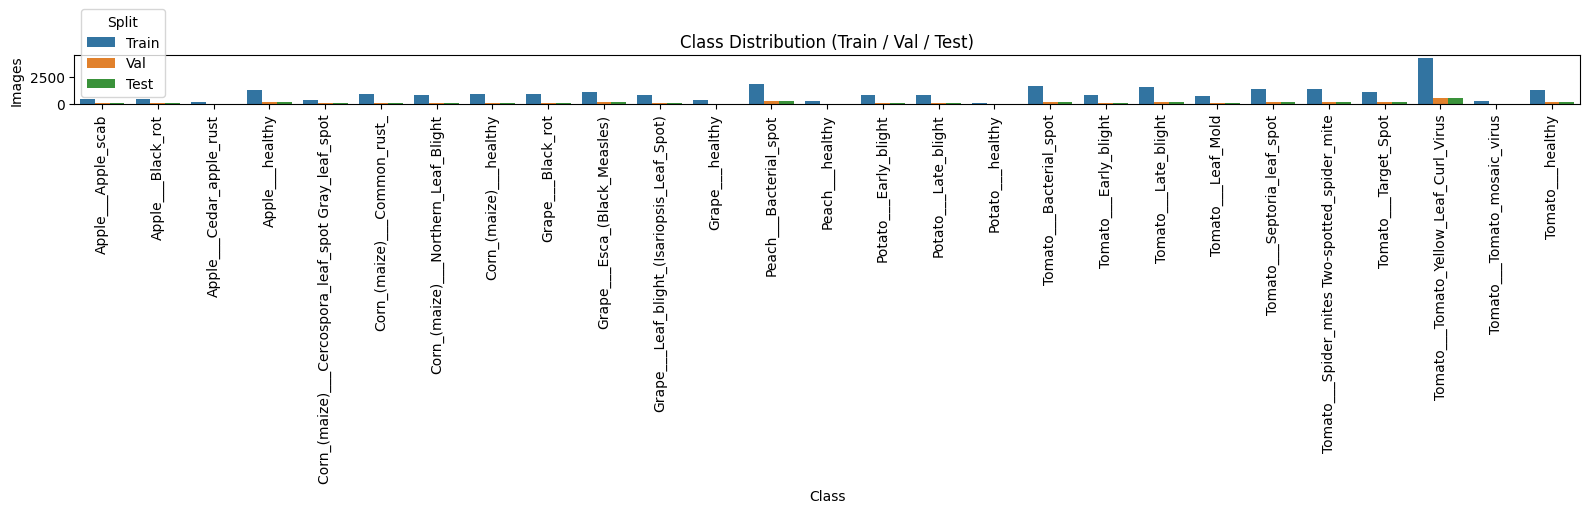

In [ ]:
df_plot = pd.DataFrame({
    "Class": class_names * 3,
    "Split": ["Train"]*len(class_names) + ["Val"]*len(class_names) + ["Test"]*len(class_names),
    "Images": [train_counts.get(c,0) for c in class_names] +
              [val_counts.get(c,0) for c in class_names] +
              [test_counts.get(c,0) for c in class_names]})

plt.figure(figsize=(16, 5))
sns.barplot(data=df_plot, x="Class", y="Images", hue="Split")
plt.xticks(rotation=90)
plt.title("Class Distribution (Train / Val / Test)")
plt.tight_layout()
plt.show()

In [ ]:
IMG_SIZE = (160, 160)
BATCH_SIZE = 32

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True,
    vertical_flip=True)

test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    train_dir, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode="categorical", shuffle=True)

val_gen = test_datagen.flow_from_directory(
    val_dir, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode="categorical", shuffle=False)

test_gen = test_datagen.flow_from_directory(
    test_dir, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode="categorical", shuffle=False)

class_labels = list(train_gen.class_indices.keys())
num_classes = len(class_labels)
print("Classes:", class_labels)

Found 27243 images belonging to 27 classes.
Found 3413 images belonging to 27 classes.
Found 3398 images belonging to 27 classes.
Classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Peach___Bacterial_spot', 'Peach___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']


In [ ]:
base_model = ResNet50V2(weights='imagenet', include_top=False, input_shape=(160, 160, 3))
base_model.trainable = False      # pehle sirf top layers train hongi

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
output = Dense(num_classes, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)
model.compile(optimizer=Adam(1e-3), loss='categorical_crossentropy', metrics=['accuracy'])

94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
MODEL_PATH = "/content/drive/MyDrive/best_model.keras"

checkpoint = ModelCheckpoint(MODEL_PATH, monitor='val_accuracy',
                             save_best_only=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, verbose=1)

In [ ]:
history1 = model.fit(train_gen, validation_data=val_gen, epochs=8,
                     callbacks=[checkpoint, reduce_lr])

Epoch 1/8
852/852 ━━━━━━━━━━━━━━━━━━━━ 0s 247ms/step - accuracy: 0.5909 - loss: 1.4331
Epoch 1: val_accuracy improved from None to 0.83211, saving model to /content/drive/MyDrive/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/best_model.keras
852/852 ━━━━━━━━━━━━━━━━━━━━ 239s 266ms/step - accuracy: 0.7020 - loss: 0.9710 - val_accuracy: 0.8321 - val_loss: 0.5316 - learning_rate: 0.0010
Epoch 2/8
852/852 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step - accuracy: 0.7957 - loss: 0.6389
Epoch 2: val_accuracy improved from 0.83211 to 0.85116, saving model to /content/drive/MyDrive/best_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/best_model.keras
852/852 ━━━━━━━━━━━━━━━━━━━━ 206s 242ms/step - accuracy: 0.8051 - loss: 0.6121 - val_accuracy: 0.8512 - val_loss: 0.4551 - learning_rate: 0.0010
Epoch 3/8
852/852 ━━━━━━━━━━━━━━━━━━━━ 0s 232ms/step - accuracy: 0.8260 - loss: 0.5362
Epoch 3: val_accuracy improved from 0.85116 to 0.85585, saving model to /conte

In [ ]:
base_model.trainable = True
for layer in base_model.layers[:-30]:      # sirf akhri 30 layers train hongi
    layer.trainable = False

model.compile(optimizer=Adam(1e-5), loss='categorical_crossentropy', metrics=['accuracy'])

history2 = model.fit(train_gen, validation_data=val_gen, epochs=14,
                     callbacks=[checkpoint, reduce_lr])

Epoch 1/14
852/852 ━━━━━━━━━━━━━━━━━━━━ 0s 249ms/step - accuracy: 0.7421 - loss: 0.9388
Epoch 1: val_accuracy improved from 0.87460 to 0.88251, saving model to /content/drive/MyDrive/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/best_model.keras
852/852 ━━━━━━━━━━━━━━━━━━━━ 244s 264ms/step - accuracy: 0.7968 - loss: 0.6617 - val_accuracy: 0.8825 - val_loss: 0.3605 - learning_rate: 1.0000e-05
Epoch 2/14
852/852 ━━━━━━━━━━━━━━━━━━━━ 0s 247ms/step - accuracy: 0.8563 - loss: 0.4348
Epoch 2: val_accuracy improved from 0.88251 to 0.90800, saving model to /content/drive/MyDrive/best_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/best_model.keras
852/852 ━━━━━━━━━━━━━━━━━━━━ 218s 255ms/step - accuracy: 0.8623 - loss: 0.4120 - val_accuracy: 0.9080 - val_loss: 0.2853 - learning_rate: 1.0000e-05
Epoch 3/14
852/852 ━━━━━━━━━━━━━━━━━━━━ 0s 248ms/step - accuracy: 0.8848 - loss: 0.3393
Epoch 3: val_accuracy improved from 0.90800 to 0.92763, saving m

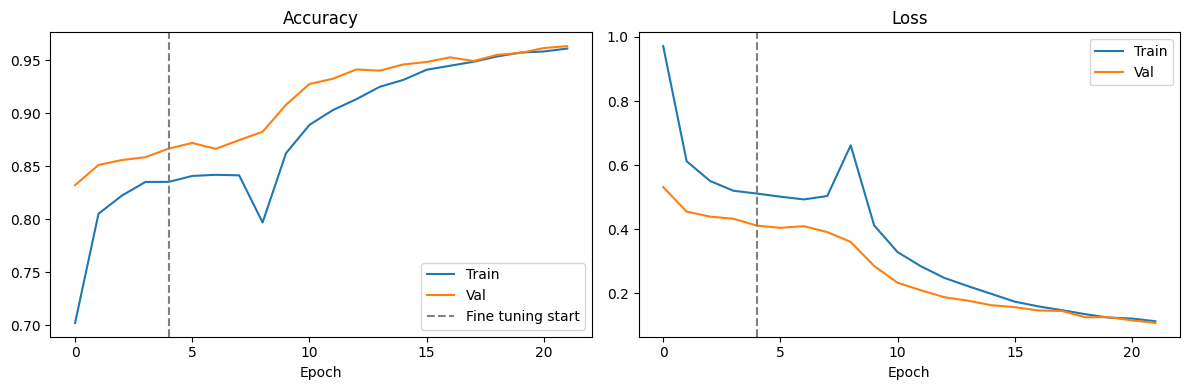

In [ ]:
acc = history1.history['accuracy'] + history2.history['accuracy']
val_acc = history1.history['val_accuracy'] + history2.history['val_accuracy']
loss = history1.history['loss'] + history2.history['loss']
val_loss = history1.history['val_loss'] + history2.history['val_loss']

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(acc, label='Train'); plt.plot(val_acc, label='Val')
plt.axvline(x=4, color='gray', linestyle='--', label='Fine tuning start')
plt.title('Accuracy'); plt.xlabel('Epoch'); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(loss, label='Train'); plt.plot(val_loss, label='Val')
plt.axvline(x=4, color='gray', linestyle='--')
plt.title('Loss'); plt.xlabel('Epoch'); plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
best_model = load_model(MODEL_PATH)

pred_probs = best_model.predict(test_gen)
y_pred = np.argmax(pred_probs, axis=1)
y_true = test_gen.classes

print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
print("Precision:", round(precision_score(y_true, y_pred, average='weighted', zero_division=0), 4))
print("Recall   :", round(recall_score(y_true, y_pred, average='weighted', zero_division=0), 4))
print("F1-Score :", round(f1_score(y_true, y_pred, average='weighted', zero_division=0), 4))
print()
print(classification_report(y_true, y_pred, target_names=class_labels, digits=4))

107/107 ━━━━━━━━━━━━━━━━━━━━ 15s 101ms/step
Accuracy : 0.965
Precision: 0.9654
Recall   : 0.965
F1-Score : 0.9648

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab     0.9836    0.9524    0.9677        63
                                 Apple___Black_rot     0.9839    0.9839    0.9839        62
                          Apple___Cedar_apple_rust     1.0000    1.0000    1.0000        27
                                   Apple___healthy     0.9760    0.9939    0.9849       164
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.8800    0.8627    0.8713        51
                       Corn_(maize)___Common_rust_     0.9917    1.0000    0.9958       119
               Corn_(maize)___Northern_Leaf_Blight     0.9381    0.9286    0.9333        98
                            Corn_(maize)___healthy     1.0000    1.0000    1.0000       116
                                 Grape___Black_rot     0

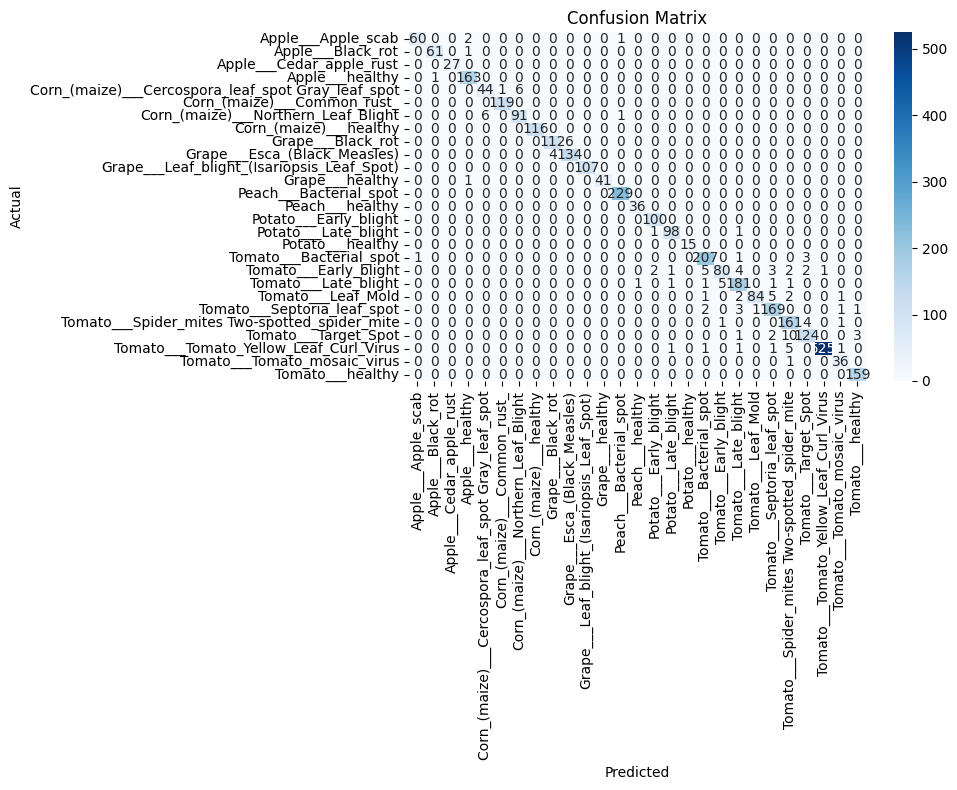

In [ ]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

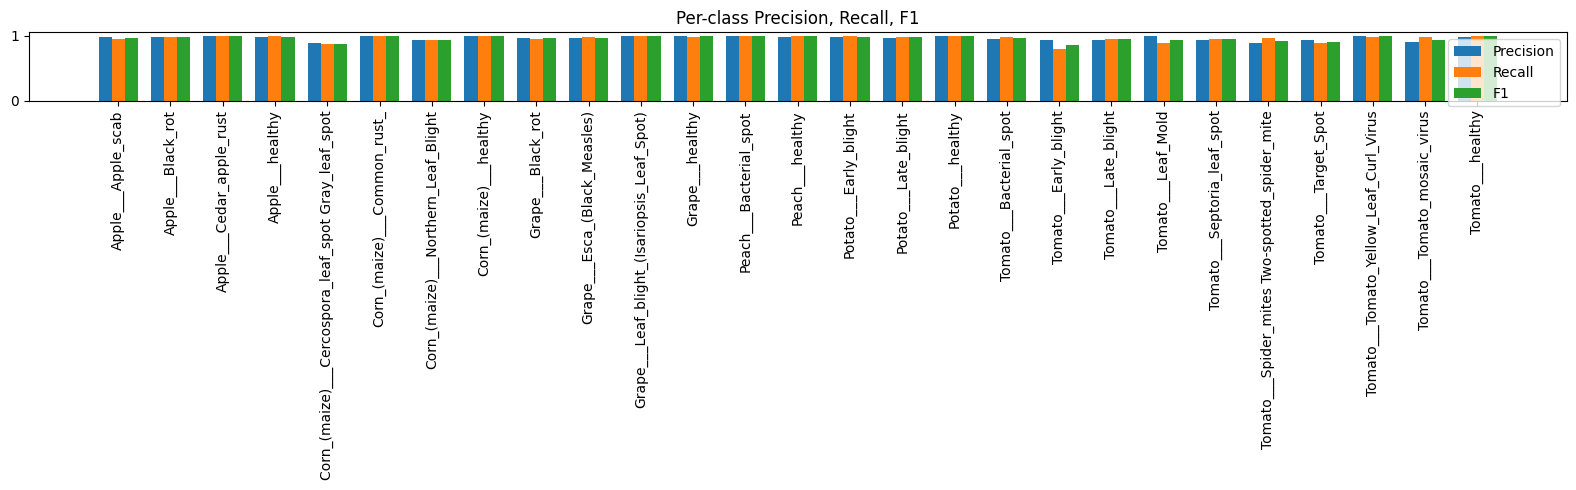

In [ ]:
p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, zero_division=0)

x = np.arange(num_classes)
plt.figure(figsize=(16, 5))
plt.bar(x - 0.25, p, 0.25, label='Precision')
plt.bar(x, r, 0.25, label='Recall')
plt.bar(x + 0.25, f1, 0.25, label='F1')
plt.xticks(x, class_labels, rotation=90)
plt.ylim(0, 1.05)
plt.legend()
plt.title('Per-class Precision, Recall, F1')
plt.tight_layout()
plt.show()

Saving corn.jpg to corn.jpg


1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


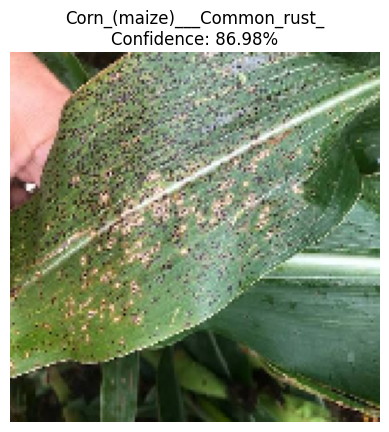

Corn_(maize)___Common_rust_: 86.98%
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 9.32%
Corn_(maize)___Northern_Leaf_Blight: 3.51%


In [ ]:
from google.colab import files

test_model = load_model(MODEL_PATH)

uploaded = files.upload()
img_path = list(uploaded.keys())[0]

img = image.load_img(img_path, target_size=(160, 160))
arr = np.expand_dims(image.img_to_array(img) / 255.0, axis=0)

pred = test_model.predict(arr)[0]
top3 = pred.argsort()[-3:][::-1]

plt.imshow(img)
plt.axis('off')
plt.title(f"{class_labels[top3[0]]}\nConfidence: {pred[top3[0]]*100:.2f}%")
plt.show()

for i in top3:
    print(f"{class_labels[i]}: {pred[i]*100:.2f}%")

In [ ]:
from google.colab import files

best_model = load_model(MODEL_PATH)
_, best_acc = best_model.evaluate(test_gen, verbose=0)
print(f"ResNet50V2 test accuracy: {best_acc*100:.2f}%")

shutil.copy(MODEL_PATH, "/content/plant_disease_best.keras")
with open("/content/class_labels.json", "w") as f:
    json.dump(class_labels, f)

shutil.copy("/content/plant_disease_best.keras", "/content/drive/MyDrive/plant_disease_best.keras")
shutil.copy("/content/class_labels.json", "/content/drive/MyDrive/class_labels.json")
print("Saved to Drive")

files.download("/content/plant_disease_best.keras")
files.download("/content/class_labels.json")

ResNet50V2 test accuracy: 96.50%
Saved to Drive


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>